# Figure 5. Full model of practice with selective elimination and recruitment

**What it is.** Averaged information with elimination and recruitment, where the coupling goes, and the closed forms against the simulated change.

**How it works.** Reads the stored output of the full model and of the runs that follow the shares, and draws the three panels.

**Files read.** `sim_out/sim_composition.npz`, `sim_out/sim_flows.npz`, `sim_out/sim_full_results.npz`, `sim_out/sim_networks.npz`, `figures/style.py`.

**To run.** Open this notebook from the `notebooks` folder of the repository, or from its root, and run all cells.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = "retina"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
import logging, os, sys
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display
logging.getLogger("matplotlib").setLevel(logging.ERROR)
plt.ioff()
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
os.chdir(ROOT)
sys.path[:0] = [str(ROOT / "figures"), str(ROOT / "code")]

In [2]:
import sys
from pathlib import Path
import numpy as np

from style import Sheet, INK, EDGE, RULE, TONE, GREY, CLEAR, R3, share_colour, tb_axes, tern_frame, tern_hfield, tern_dots, tern_xy, net_above

src = ROOT / "sim_out"
d = np.load(src / "sim_full_results.npz")
N, A_MS, ID = 20, 12.8, 4.0
BETA = 94.7 / np.log2(N)
CEIL = np.log2(N)
COMP = np.load(src / "sim_composition.npz")
FL = np.load(src / "sim_flows.npz")

S = Sheet(6.5, 2.38)
axA = S.ax(0.42, 0.40, 1.36, 1.72)
axT = S.ax(2.28, 0.04, 2.00, 2.12)
axC = S.ax(4.74, 0.40, 1.36, 1.72)
NW = np.load(src / "sim_networks.npz")

## A, elimination and recruitment

In [3]:
ax = axA
t = d["steps"]
ax.axhline(CEIL, color=RULE, lw=0.6, ls=(0, (2.4, 1.6)))
ax.text(2960, CEIL + 0.04, "ceiling log$_2$ 20", ha="right", va="bottom", fontsize=6.0, color=EDGE, **CLEAR)
ax.axvline(200, color=RULE, lw=0.5, ls=":")
ax.text(240, 1.56, "elimination starts", fontsize=6.0, color=EDGE, va="bottom")
ax.plot(t, d["fixed_no_elimination"], color=TONE["small-world"], lw=1.2, ls=(0, (3.0, 1.6)))
ax.plot(t, d["freeing"], color=TONE["scale-free"], lw=1.2, ls=(0, (4.0, 1.4, 1.0, 1.4)))
ax.plot(t, d["fixed"], color=INK, lw=1.5)
ax.text(2960, d["fixed_no_elimination"][-1] + 0.06, "no elimination", ha="right", va="bottom", fontsize=6.2, color=EDGE)
ax.text(2000, d["fixed"][2000] + 0.14, "fixed set", ha="left", va="bottom", fontsize=6.2)
ax.annotate("10 elements\nrecruited,\nsteps 25 to 250", xy=(150, d["freeing"][150]), xytext=(330, 2.62),
            fontsize=6.2, color=TONE["scale-free"], ha="left", va="top",
            arrowprops=dict(arrowstyle="-", color=TONE["scale-free"], lw=0.6))
ax.set_xlabel("practice step $t$", labelpad=1)
ax.set_ylabel(r"$H(t)$, bits", labelpad=1.5)
ax.set_xlim(0, 3000)
ax.set_ylim(1.4, 4.6)
ax2 = ax.twinx()
lo, hi = ax.get_ylim()
ax2.set_ylim(A_MS + BETA * lo * ID, A_MS + BETA * hi * ID)
ax2.set_ylabel("$T$ of a 4-bit task, ms", labelpad=2)
tb_axes(ax, xticks=[0, 1500, 3000], yticks=[1.5, 3.0, 4.5], twin=ax2, twin_ticks=[150, 275, 400])

## B, where the coupling goes

In [4]:
ax = axT
tern_frame(ax, grid=(), outline="dotted", all_ticks=True, tick_fs=6.4, tick_color=INK, corner_fs=7.2,
           ticks=(0.0, 0.5, 1.0), edge_titles=("chance hubs", "peripheral elements", "fit elements"),
           top=0.30, slide=0.09)
LAB = [(0.864, 0.112, 0.024), (0.755, 0.202, 0.043), (0.618, 0.315, 0.067), (0.429, 0.471, 0.101)]
tern_hfield(ax, (3, 14, 3), [2.5, 3.0, 3.5, 4.0], CEIL, fill=False, lw=1.4, label_at=[tuple(np.ravel(tern_xy(c_))) for c_ in LAB])
NS = len(FL["starts"])
for i in range(NS):
    tern_dots(ax, FL[f"f5_{i}"][:, [1, 2, 0]], every=200)
x0, y0 = tern_xy(FL["f5_0"][0][[1, 2, 0]])
ax.plot(x0, y0, "o", ms=4.4, color=share_colour(0.0), mec=EDGE, mew=0.6, zorder=7)
ax.text(x0[0], y0[0] - 0.045, "even ring", fontsize=6.4, ha="center", va="top", color=EDGE)
ends = [tern_xy(FL["f5_0"][r_][[1, 2, 0]]) for r_ in (0, -1)]
ends = [(float(x_[0]), float(y_[0])) for x_, y_ in ends]
NET_W = 0.58
insB = [net_above(S, ax, 0.06, 0.80, NET_W, NW["f5_A0"], "step 0\n$H$ = {:.2f} bits".format(np.log2(20)), "o", ends[0],
                  rad=-0.45, turn=35),
        net_above(S, ax, 0.94, 0.80, NET_W, NW["f5_A"], "step 3,000\n$H$ = {:.2f} bits".format(float(NW["f5_H"])), "D",
                  ends[1], rad=-0.30, turn=40)]

## C, Equations 14 and 15 and the simulations

In [5]:
ax = axC
p, r, g = d["pred"], d["real"], d["regime"]
lim = 0.39
ax.plot([-lim, lim], [-lim, lim], color=RULE, lw=0.6)
ax.plot(p[g == "fixed"], r[g == "fixed"], "o", ms=3.0, color=INK, mec="white", mew=0.3, label="fixed set", zorder=3)
ax.plot(p[g == "freeing"], r[g == "freeing"], "o", ms=3.0, color="white", mec=TONE["scale-free"], mew=0.8,
        label="with recruitment", zorder=3)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("predicted change in $H$, bits", labelpad=1)
ax.set_ylabel("simulated change, bits", labelpad=1.5)
ax.legend(fontsize=6.0, loc="upper left", handletextpad=0.2, borderaxespad=0.1, labelspacing=0.15, handlelength=1.0)
axD = ax.twinx()
axD.set_ylim(-lim * BETA * ID, lim * BETA * ID)
axD.set_ylabel("change in $T$ of a 4-bit task, ms", labelpad=2)
tb_axes(ax, xticks=[-0.3, 0, 0.3], xlim=(-lim, lim), yticks=[-0.3, 0, 0.3], ylim=(-lim, lim), twin=axD,
        twin_ticks=[-30, 0, 30])

S.head_over(axA, "A", "Elimination and recruitment")
S.head("B", "Where coupling goes", 2.28 + 2.00 / 2)
S.head_over(axC, "C", "Equations 14 and 15")

r_ = np.corrcoef(p, r)[0, 1]
sl = np.polyfit(p, r, 1)[0]
print(f"fixed H: {d['fixed'][0]:.2f} -> {d['fixed'][1000]:.2f} (1000) -> {d['fixed'][-1]:.2f} (3000); "
      f"no elimination {d['fixed_no_elimination'][1000]:.2f}, {d['fixed_no_elimination'][-1]:.2f}; "
      f"recruitment {d['freeing'][0]:.2f} -> {d['freeing'][250]:.2f} (250) -> {d['freeing'][1000]:.2f} -> {d['freeing'][-1]:.2f}")
print(f"windows: r = {r_:.3f}, slope {sl:.2f}, same sign {int(np.sum(np.sign(p) == np.sign(r)))} of {len(p)}")
for i, st in enumerate(FL["starts"]):
    c_ = FL[f"f5_{i}"]
    print(f"panel B, start {tuple(int(x) for x in st)}: shares {np.round(c_[0], 3)} -> {np.round(c_[1000], 3)} (1000) -> {np.round(c_[-1], 3)}")

fixed H: 4.32 -> 3.01 (1000) -> 1.65 (3000); no elimination 3.81, 3.66; recruitment 3.32 -> 4.05 (250) -> 3.70 -> 2.49
windows: r = 0.994, slope 0.98, same sign 60 of 60
panel B, start (2, 2, 2): shares [0.15 0.15 0.7 ] -> [0.688 0.137 0.175] (1000) -> [0.989 0.011 0.   ]
panel B, start (1, 2, 3): shares [0.058 0.192 0.75 ] -> [0.475 0.201 0.324] (1000) -> [0.952 0.036 0.012]
panel B, start (1, 4, 2): shares [0.068 0.273 0.659] -> [0.521 0.197 0.282] (1000) -> [0.966 0.028 0.005]
panel B, start (1, 6, 2): shares [0.06 0.36 0.58] -> [0.489 0.219 0.292] (1000) -> [0.957 0.034 0.009]
panel B, start (3, 2, 2): shares [0.205 0.159 0.636] -> [0.74  0.119 0.141] (1000) -> [0.991 0.009 0.   ]
panel B, start (5, 2, 2): shares [0.3  0.14 0.56] -> [0.802 0.095 0.103] (1000) -> [0.994 0.006 0.   ]
panel B, start (8, 2, 2): shares [0.414 0.103 0.483] -> [0.85  0.076 0.075] (1000) -> [0.996 0.004 0.   ]


## The figure

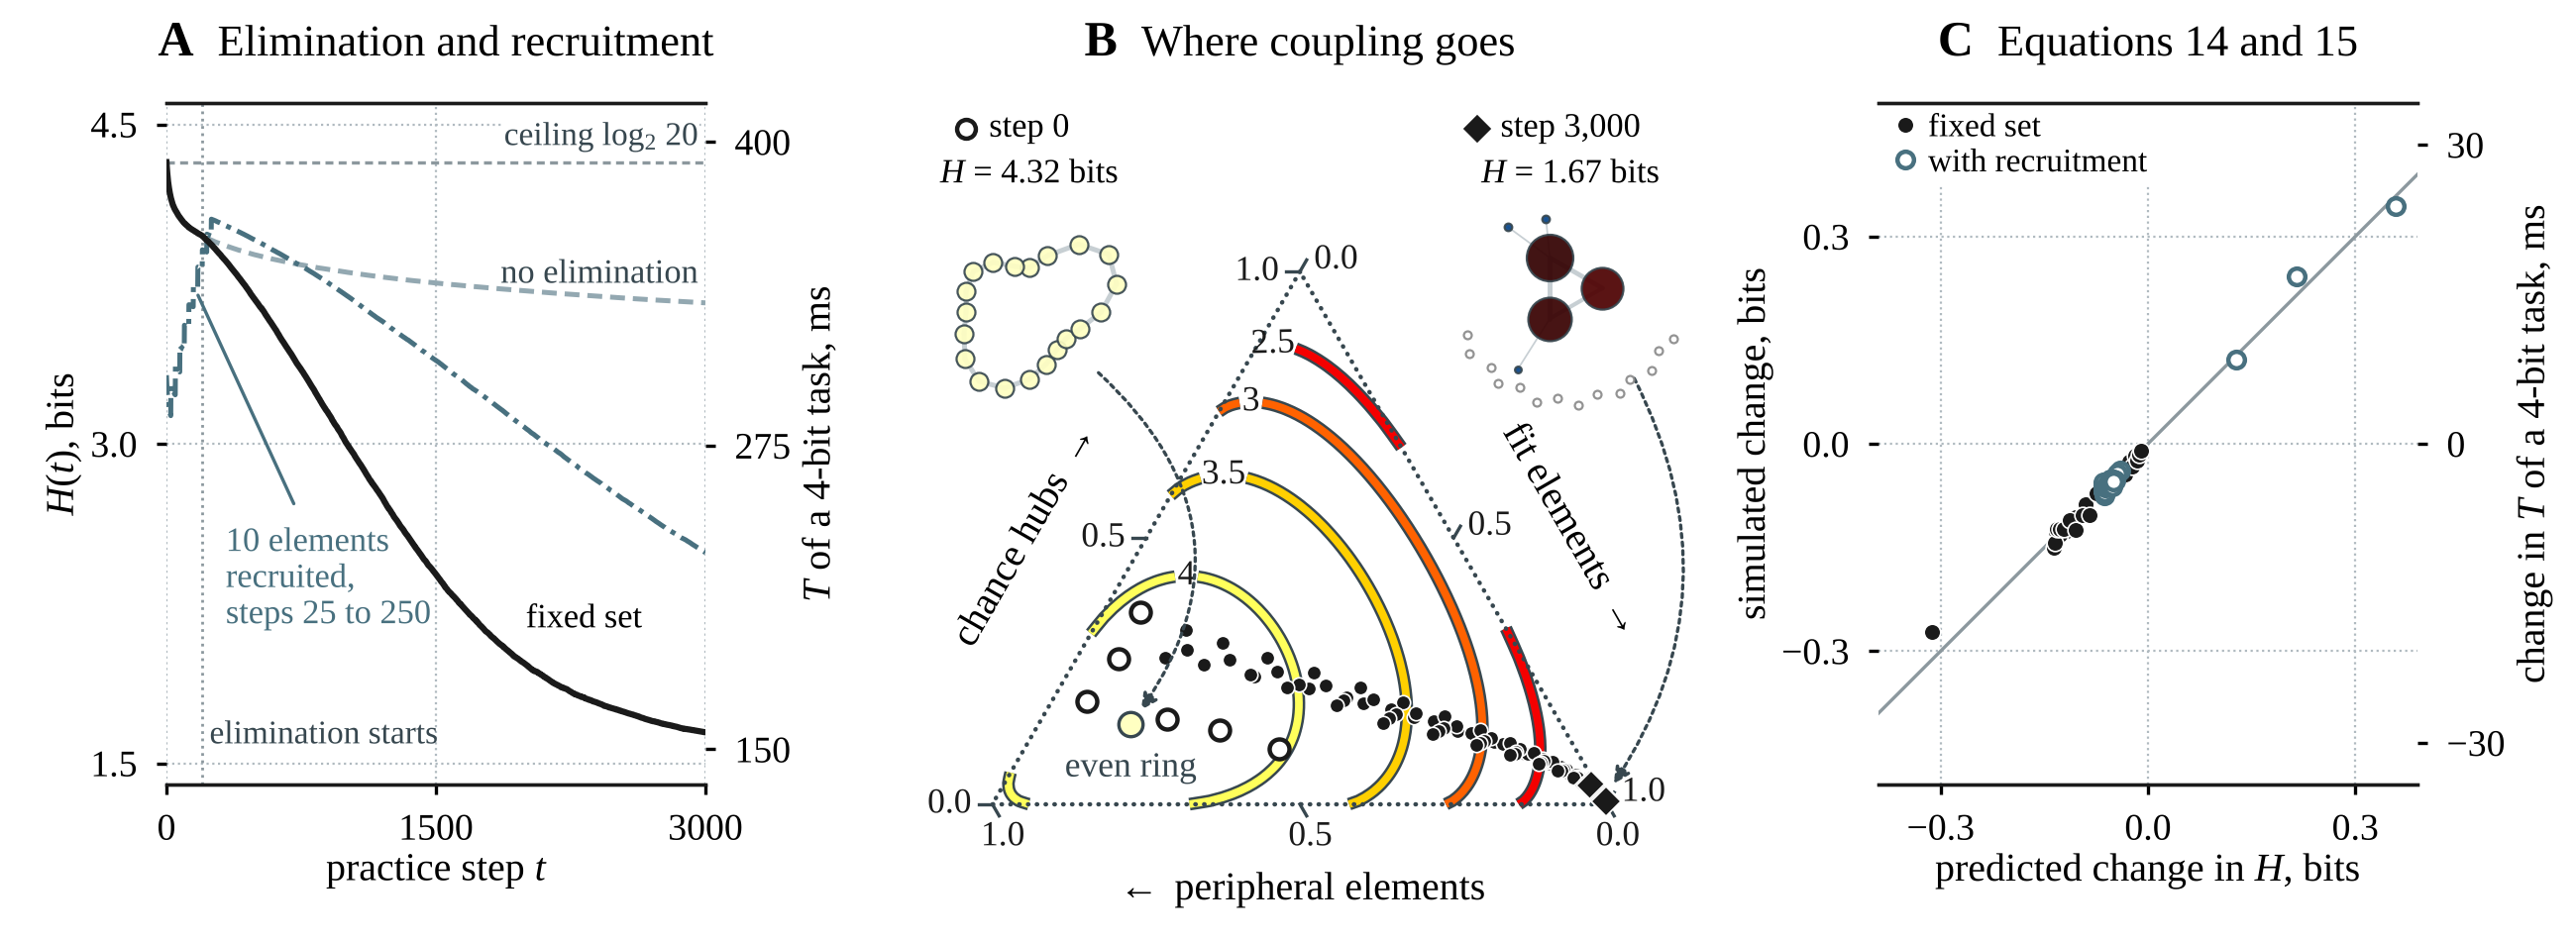

In [6]:
from style import bolden
bolden(S.fig)
display(S.fig)
plt.close("all")

## In the paper

Printed here, then as the manuscript or the Supplemental Material gives it.

- `fixed H: 4.32 -> 3.01 (1000) -> 1.65 (3000)`, `no elimination 3.81, 3.66`, `recruitment 3.32 -> 4.05 (250) -> 3.70 -> 2.49`: the same values in the main text.
- `windows: r = 0.994, slope 0.98, same sign 60 of 60`: Figure 5C.
- `start (2, 2, 2)`, first share 0.688 at step 1,000 and 0.989 at step 3,000: 0.69 and 0.99 of all link ends. Over the seven starts it ends between 0.952 and 0.996, the 0.95 to 1.00 of the text.